In [1]:
import sys
import pandas as pd

print("Python environment:", sys.executable)
print("pandas version:", pd.__version__)

Python environment: /Users/javiermorande/Desktop/olist-delivery-risk/.venv/bin/python
pandas version: 3.1.1


In [2]:
from pathlib import Path

# Find the project folder from either the notebook or project directory
project_dir = Path.cwd()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent

# Load the orders CSV into a pandas table
orders = pd.read_csv(
    project_dir / "data" / "raw" / "olist_orders_dataset.csv"
)

print(f"Rows: {orders.shape[0]:,}")
print(f"Columns: {orders.shape[1]}")

orders.head()

Rows: 99,441
Columns: 8


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


## 2. Data quality checks

Check for duplicate order IDs and missing values before analysing delivery performance.

In [3]:
print("Duplicate order IDs:", orders["order_id"].duplicated().sum())

missing_summary = pd.DataFrame({
    "missing_count": orders.isna().sum(),
    "missing_percent": (orders.isna().mean() * 100).round(2)
})

missing_summary.sort_values("missing_count", ascending=False)

Duplicate order IDs: 0


,missing_count,missing_percent
order_delivered_customer_date,2965,2.98
order_delivered_carrier_date,1783,1.79
order_approved_at,160,0.16
order_id,0,0.00
customer_id,0,0.00
order_status,0,0.00
order_purchase_timestamp,0,0.00
order_estimated_delivery_date,0,0.00


### Investigating missing delivery dates

Check whether missing delivery dates belong to canceled, unfinished, or delivered orders.

In [4]:
status_check = (
    orders.assign(
        missing_delivery_date=orders["order_delivered_customer_date"].isna()
    )
    .groupby("order_status")
    .agg(
        total_orders=("order_id", "size"),
        missing_delivery_dates=("missing_delivery_date", "sum")
    )
)

status_check.sort_values("total_orders", ascending=False)

,total_orders,missing_delivery_dates
order_status,,
delivered,96478,8
shipped,1107,1107
canceled,625,619
unavailable,609,609
invoiced,314,314
processing,301,301
created,5,5
approved,2,2


### Findings from the initial data audit

- Order IDs are unique.
- Most missing delivery dates belong to orders not marked as delivered.
- Eight delivered orders have no recorded delivery date.
- Six canceled orders have a recorded delivery date.

For the initial late-delivery analysis, we will use orders marked
as delivered with valid actual and estimated delivery dates.
Other orders will remain in the original data but be excluded
from this calculation.

This means our initial results describe completed deliveries,
not all orders placed.

## 3. Checking date validity

Convert timestamp columns into datetime values.
Distinguish existing missing values from dates that cannot be parsed.

In [5]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

# Use a separate copy so the original orders table stays unchanged
orders_dates = orders.copy()
date_checks = []

for column in date_columns:
    original = orders[column]

    converted = pd.to_datetime(
        original,
        format="%Y-%m-%d %H:%M:%S",
        errors="coerce"
    )

    orders_dates[column] = converted

    date_checks.append({
        "column": column,
        "originally_missing": original.isna().sum(),
        "invalid_dates": (original.notna() & converted.isna()).sum()
    })

pd.DataFrame(date_checks)

,column,originally_missing,invalid_dates
0,order_purchase_timestamp,0,0
1,order_approved_at,160,0
2,order_delivered_carrier_date,1783,0
3,order_delivered_customer_date,2965,0
4,order_estimated_delivery_date,0,0


### Checking the order of events

Look for timestamps recorded in an unexpected sequence.
Flag these records for review without deleting them.

In [6]:
sequence_flags = pd.DataFrame({
    "approval_before_purchase":
        orders_dates["order_approved_at"]
        < orders_dates["order_purchase_timestamp"],

    "carrier_before_approval":
        orders_dates["order_delivered_carrier_date"]
        < orders_dates["order_approved_at"],

    "delivery_before_carrier":
        orders_dates["order_delivered_customer_date"]
        < orders_dates["order_delivered_carrier_date"],

    "delivery_before_purchase":
        orders_dates["order_delivered_customer_date"]
        < orders_dates["order_purchase_timestamp"],

    "estimated_date_before_purchase_date":
        orders_dates["order_estimated_delivery_date"].dt.normalize()
        < orders_dates["order_purchase_timestamp"].dt.normalize()
})

sequence_flags.sum().rename("flagged_orders").to_frame()

,flagged_orders
approval_before_purchase,0
carrier_before_approval,1359
delivery_before_carrier,23
delivery_before_purchase,0
estimated_date_before_purchase_date,0


In [7]:
timing_gaps = pd.DataFrame({
    "approval_to_carrier_hours": (
        orders_dates["order_delivered_carrier_date"]
        - orders_dates["order_approved_at"]
    ).dt.total_seconds() / 3600,

    "carrier_to_customer_hours": (
        orders_dates["order_delivered_customer_date"]
        - orders_dates["order_delivered_carrier_date"]
    ).dt.total_seconds() / 3600
})

timing_gaps.where(timing_gaps < 0).describe().round(2)

,approval_to_carrier_hours,carrier_to_customer_hours
count,1359.00,23.00
mean,-24.75,-78.46
std,115.31,89.31
min,-4109.26,-386.31
25%,-25.96,-128.76
50%,-17.17,-39.86
75%,-1.42,-23.34
max,-0.01,-0.39


## 4. Initial late-delivery rate

Use delivered orders with actual and estimated delivery dates.
An order is late if it arrives on a calendar date after the promised date.
Arrival on the promised day counts as on time.

Timestamp sequence anomalies remain flagged for further investigation.

In [8]:
eligible = (
    orders_dates["order_status"].eq("delivered")
    & orders_dates["order_delivered_customer_date"].notna()
    & orders_dates["order_estimated_delivery_date"].notna()
)

delivery_analysis = orders_dates.loc[eligible].copy()

actual_day = (
    delivery_analysis["order_delivered_customer_date"].dt.normalize()
)
promised_day = (
    delivery_analysis["order_estimated_delivery_date"].dt.normalize()
)

delivery_analysis["days_after_promise"] = (
    actual_day - promised_day
).dt.days

delivery_analysis["is_late"] = (
    delivery_analysis["days_after_promise"] > 0
)

print(f"Orders included: {len(delivery_analysis):,}")
print(f"Orders excluded: {(~eligible).sum():,}")
print(f"Late orders: {delivery_analysis['is_late'].sum():,}")
print(f"Late-delivery rate: {delivery_analysis['is_late'].mean():.2%}")

Orders included: 96,470
Orders excluded: 2,971
Late orders: 6,534
Late-delivery rate: 6.77%


### Initial finding

Among 96,470 delivered orders with recorded actual and estimated
delivery dates, 6,534 (6.77%) arrived after the promised calendar date.

The calculation excludes 2,971 orders. These results describe
eligible completed deliveries, not all orders placed.

Late deliveries are the minority class. Always predicting “on time”
would achieve 93.23% accuracy on this population but identify no late
deliveries. Model evaluation must therefore go beyond accuracy.

## 5. How severe are late deliveries?

Measure the delay in calendar days for orders that arrived late.

In [9]:
late_days = delivery_analysis.loc[
    delivery_analysis["is_late"],
    "days_after_promise"
]

print(f"Late orders: {len(late_days):,}")
print(f"Median delay: {late_days.median():.1f} days")
print(f"Average delay: {late_days.mean():.1f} days")
print(f"Longest delay: {late_days.max():,} days")
print(f"More than 7 days late: {(late_days > 7).mean():.1%}")
print(f"More than 30 days late: {(late_days > 30).mean():.1%}")

Late orders: 6,534
Median delay: 7.0 days
Average delay: 10.6 days
Longest delay: 188 days
More than 7 days late: 43.8%
More than 30 days late: 5.3%


### Inspecting the longest delays

Review the five largest delays and their timestamps.
Extreme values are investigated rather than automatically removed.

In [10]:
delivery_analysis.nlargest(5, "days_after_promise")[
    [
        "order_id",
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_estimated_delivery_date",
        "order_delivered_customer_date",
        "days_after_promise"
    ]
].T

,55619,19590,11399,81401,89130
order_id,1b3190b2dfa9d789e1f14c05b647a14a,ca07593549f1816d26a572e06dc1eab6,47b40429ed8cce3aee9199792275433f,2fe324febf907e3ea3f2aa9650869fa5,285ab9426d6982034523a855f55a885e
order_purchase_timestamp,2018-02-23 14:57:35,2017-02-21 23:31:27,2018-01-03 09:44:01,2017-03-13 20:17:10,2017-03-08 22:47:40
order_approved_at,2018-02-23 15:16:14,2017-02-23 02:35:15,2018-01-03 10:31:15,2017-03-13 20:17:10,2017-03-08 22:47:40
order_delivered_carrier_date,2018-02-26 18:49:07,2017-03-08 13:47:46,2018-02-06 01:48:28,2017-03-17 07:23:53,2017-03-09 08:53:20
order_estimated_delivery_date,2018-03-15 00:00:00,2017-03-22 00:00:00,2018-01-19 00:00:00,2017-04-05 00:00:00,2017-04-06 00:00:00
order_delivered_customer_date,2018-09-19 23:24:07,2017-09-19 14:36:39,2018-07-13 20:51:31,2017-09-19 17:00:07,2017-09-19 14:00:04
days_after_promise,188,181,175,167,166


### Review of extreme delays

The five longest recorded delays range from 166 to 188 days.
Their purchase, approval, carrier handover, and customer delivery
timestamps occur in the expected sequence.

Three share a recorded delivery date of 19 September 2017.
The available data does not establish whether this reflects actual
deliveries or an administrative update.

These records are retained for now. Extreme delays alone are not
sufficient grounds for deleting observations.

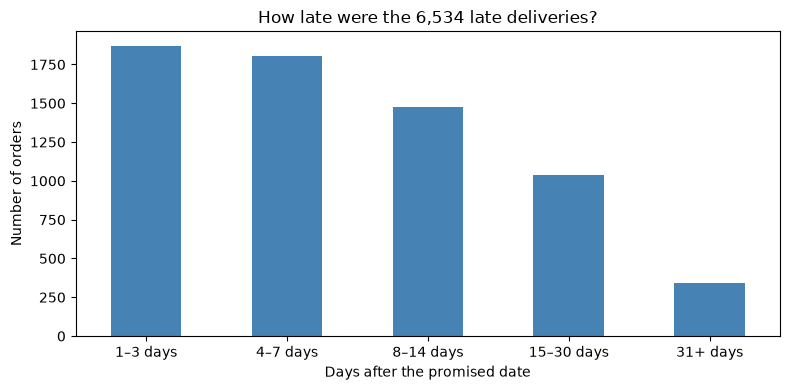

In [11]:
import matplotlib.pyplot as plt

delay_groups = pd.cut(
    late_days,
    bins=[0, 3, 7, 14, 30, float("inf")],
    labels=["1–3 days", "4–7 days", "8–14 days", "15–30 days", "31+ days"]
)

counts = delay_groups.value_counts(sort=False)

ax = counts.plot.bar(figsize=(8, 4), color="steelblue", rot=0)
ax.set_title("How late were the 6,534 late deliveries?")
ax.set_xlabel("Days after the promised date")
ax.set_ylabel("Number of orders")

plt.tight_layout()
plt.show()

### Interpretation of delivery delays

Among the 6,534 late deliveries:

- The largest group arrived 1–3 days after the promised date.
- 56.2% arrived within 7 days after the promised date.
- 43.8% were more than 7 days late, and 5.3% were more than 30 days late.
- The median delay was 7 days. The higher average of 10.6 days
  reflects the influence of some very long delays.

The chart shows that delays vary considerably in severity.
These percentages describe late deliveries only, not all orders.

The delay ranges have different widths, so the bars compare total
orders per range rather than frequency per individual day.

## 6. Delivery performance by purchase month

Compare late-delivery rates and order counts by the month the order
was placed. Results include only eligible completed deliveries.
Small or incomplete months require cautious interpretation.

In [12]:
monthly_delivery = (
    delivery_analysis.assign(
        purchase_month=delivery_analysis[
            "order_purchase_timestamp"
        ].dt.to_period("M")
    )
    .groupby("purchase_month")
    .agg(
        total_orders=("order_id", "size"),
        late_orders=("is_late", "sum"),
        late_rate=("is_late", "mean")
    )
)

monthly_delivery["late_rate_percent"] = (
    monthly_delivery["late_rate"] * 100
).round(2)

monthly_delivery[
    ["total_orders", "late_orders", "late_rate_percent"]
]

,total_orders,late_orders,late_rate_percent
purchase_month,,,
2016-09,1,1,100.00
2016-10,265,2,0.75
2016-12,1,0,0.00
2017-01,750,22,2.93
2017-02,1653,49,2.96
2017-03,2546,116,4.56
2017-04,2303,151,6.56
2017-05,3545,106,2.99
2017-06,3135,95,3.03


### Monthly findings

Late-delivery rates varied substantially by purchase month.
March 2018 had a rate of 18.96%, compared with 1.16% in June 2018.

September and December 2016 each contain only one eligible order,
so their percentages should not be interpreted as reliable trends.

Order volume alone does not explain the variation. Further analysis
is needed before attributing the peaks to specific causes.

These results cover eligible completed deliveries. We must inspect
the full dataset's time coverage and excluded orders before deciding
which months are suitable for model training and evaluation.

The variation supports evaluating models chronologically:
training on earlier orders and testing on later orders.

### Checking monthly data coverage

Compare all orders with those included in the delivery analysis.
Excluded orders have unknown or unsuitable outcomes for our current
late-delivery calculation; they are not counted as on time.

In [13]:
monthly_coverage = (
    orders_dates.assign(
        purchase_month=orders_dates[
            "order_purchase_timestamp"
        ].dt.to_period("M"),
        included=eligible
    )
    .groupby("purchase_month")
    .agg(
        all_orders=("order_id", "size"),
        included_orders=("included", "sum")
    )
)

monthly_coverage["excluded_orders"] = (
    monthly_coverage["all_orders"]
    - monthly_coverage["included_orders"]
)

monthly_coverage["included_percent"] = (
    monthly_coverage["included_orders"]
    / monthly_coverage["all_orders"] * 100
).round(2)

monthly_coverage


,all_orders,included_orders,excluded_orders,included_percent
purchase_month,,,,
2016-09,4,1,3,25.00
2016-10,324,265,59,81.79
2016-12,1,1,0,100.00
2017-01,800,750,50,93.75
2017-02,1780,1653,127,92.87
2017-03,2682,2546,136,94.93
2017-04,2404,2303,101,95.80
2017-05,3700,3545,155,95.81
2017-06,3245,3135,110,96.61


### Monthly coverage findings

January 2017–August 2018 has substantial order volumes and inclusion
rates of approximately 93–99%.

Coverage in 2016 is sparse. September–October 2018 contains only
20 orders, none eligible for the current delivery analysis.

January 2017–August 2018 is a candidate analysis window, not yet a
final modelling window. Monthly counts alone do not establish that
each month is complete.

Excluded orders are not treated as on time.

In [14]:
date_ranges = orders_dates[date_columns].agg(["min", "max"]).T
date_ranges.columns = ["earliest_recorded", "latest_recorded"]

date_ranges

,earliest_recorded,latest_recorded
order_purchase_timestamp,2016-09-04 21:15:19,2018-10-17 17:30:18
order_approved_at,2016-09-15 12:16:38,2018-09-03 17:40:06
order_delivered_carrier_date,2016-10-08 10:34:01,2018-09-11 19:48:28
order_delivered_customer_date,2016-10-11 13:46:32,2018-10-17 13:22:46
order_estimated_delivery_date,2016-09-30 00:00:00,2018-11-12 00:00:00


### Date coverage limitations

Recorded purchases extend to 17 October 2018, while approvals
extend only to 3 September 2018. Estimated delivery dates extend
to 12 November 2018.

These differences reinforce caution about orders near the end
of the dataset. The latest timestamp does not establish when the
data was extracted or whether every delivery outcome was observed.

January 2017–August 2018 remains a candidate analysis window.

In [15]:
end_period_orders = orders_dates.loc[
    orders_dates["order_purchase_timestamp"] >= "2018-09-01"
]

end_period_orders.groupby("order_status").agg(
    orders=("order_id", "size"),
    recorded_approvals=("order_approved_at", "count"),
    recorded_deliveries=("order_delivered_customer_date", "count")
)

,orders,recorded_approvals,recorded_deliveries
order_status,,,
canceled,19,0,0
shipped,1,1,0


### Orders placed in September–October 2018

Of the 20 orders in these months:
- 19 were canceled, with no recorded approval or delivery dates.
- One was marked shipped, with an approval date but no delivery date.

None qualifies for our completed-delivery analysis.
We cannot determine the shipped order's eventual outcome from this data.

## 7. Inspecting customer data

Load customer locations and verify the customer ID before
joining them to orders.

In [16]:
customers = pd.read_csv(
    project_dir / "data" / "raw" / "olist_customers_dataset.csv",
    dtype={"customer_zip_code_prefix": "string"}
)

print(f"Customer rows: {len(customers):,}")
print(f"Missing customer IDs: {customers['customer_id'].isna().sum():,}")
print(f"Duplicate customer IDs: {customers['customer_id'].duplicated().sum():,}")

customers.head()

Customer rows: 99,441
Missing customer IDs: 0
Duplicate customer IDs: 0


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,09790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,01151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,08775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


### Joining customer locations to deliveries

Keep every eligible delivery and attach its customer location.
Verify that the join preserves the number of orders and identify
unmatched customers or missing locations.

In [17]:
delivery_customers = delivery_analysis.merge(
    customers,
    on="customer_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

print(f"Rows before join: {len(delivery_analysis):,}")
print(f"Rows after join: {len(delivery_customers):,}")
print(
    "Orders without a customer match:",
    delivery_customers["_merge"].eq("left_only").sum()
)

location_columns = ["customer_city", "customer_state"]

missing_locations = (
    delivery_customers[location_columns]
    .replace(r"^\s*$", pd.NA, regex=True)
    .isna()
    .sum()
)

missing_locations.rename("missing_or_blank").to_frame()

Rows before join: 96,470
Rows after join: 96,470
Orders without a customer match: 0


,missing_or_blank
customer_city,0
customer_state,0


## 8. Late-delivery rates by customer state

Compare late-delivery rates alongside order counts.
Small groups can produce unstable percentages. These comparisons
describe associations, not proof that location causes delays.

In [18]:
state_summary = (
    delivery_customers.groupby("customer_state")
    .agg(
        total_orders=("order_id", "size"),
        late_orders=("is_late", "sum"),
        late_rate=("is_late", "mean")
    )
)

state_summary["late_rate_percent"] = (
    state_summary["late_rate"] * 100
).round(2)

state_summary[
    ["total_orders", "late_orders", "late_rate_percent"]
].sort_values("late_rate_percent", ascending=False)

,total_orders,late_orders,late_rate_percent
customer_state,,,
AL,397,85,21.41
MA,717,125,17.43
SE,335,51,15.22
PI,476,66,13.87
CE,1279,176,13.76
RR,41,5,12.20
BA,3256,396,12.16
RJ,12350,1495,12.11
PA,946,106,11.21


### Findings by customer state

AL had the highest observed late-delivery rate: 21.41% across 397 orders.

RJ combined an above-average late rate of 12.11% with a substantial
volume of 1,495 late orders.

SP had a below-average late rate of 4.49%, but the largest number
of late orders (1,820) due to its much larger order volume.

Rates based on small groups, such as RR with 41 orders, require
caution. Rate rankings and affected-order counts answer different
business questions.

These comparisons do not establish that customer location causes
delays. Differences in sellers, products, purchase periods, and
promised delivery windows may also contribute.

### Comparing delay rates and affected order counts

The left chart shows how common late deliveries were in each state.
The right chart shows how many orders were late.

Both charts use the same state order. Labels show the total number
of eligible deliveries, helping identify states with small samples.

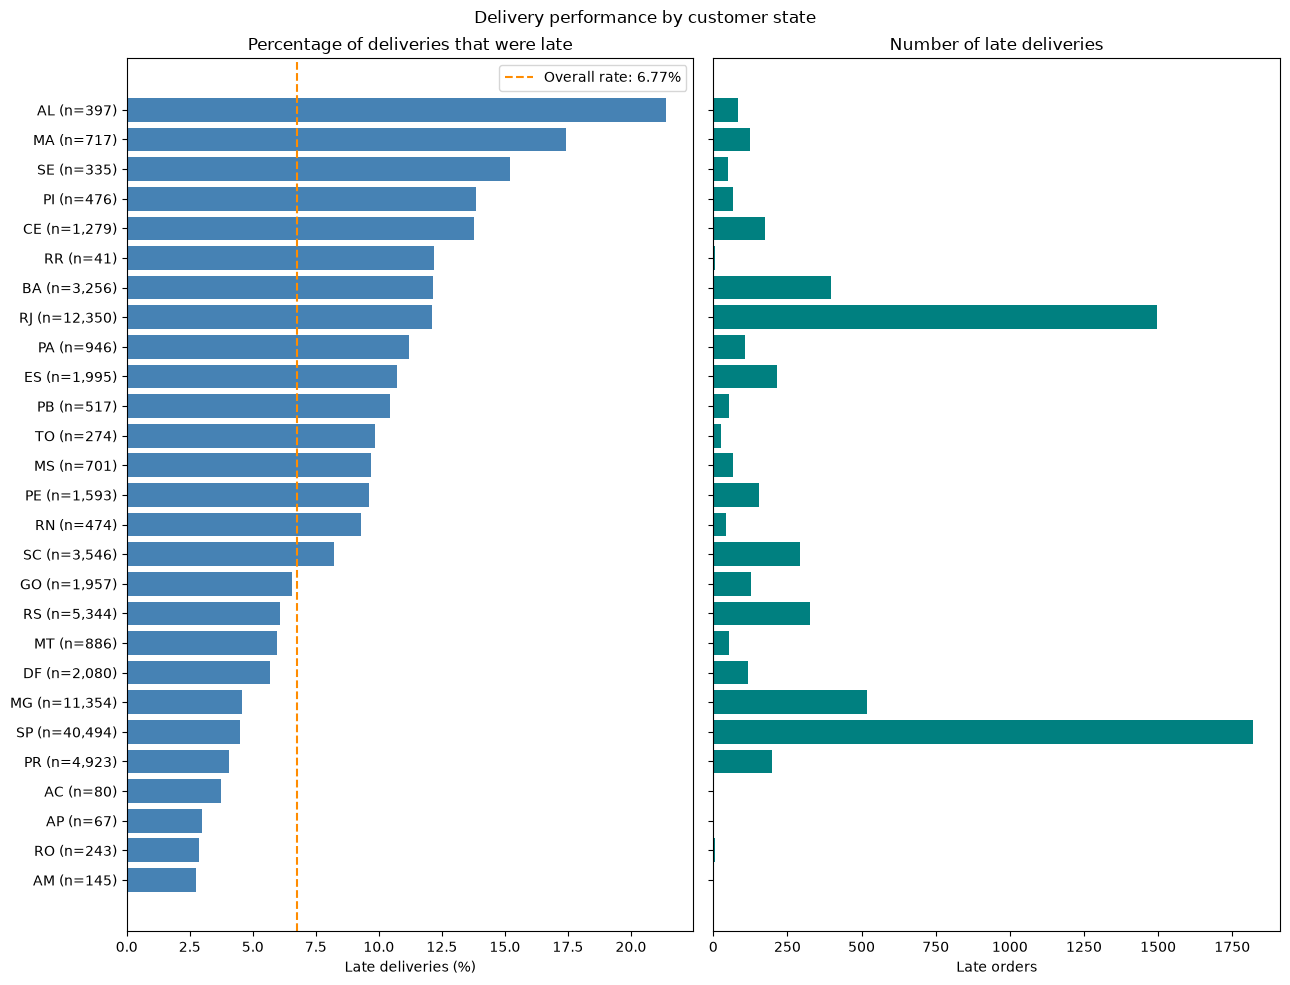

In [19]:
plot_data = state_summary.sort_values("late_rate_percent")

labels = [
    f"{state} (n={int(total):,})"
    for state, total in plot_data["total_orders"].items()
]

fig, axes = plt.subplots(
    1, 2, figsize=(13, 10), sharey=True
)

axes[0].barh(
    labels,
    plot_data["late_rate_percent"],
    color="steelblue"
)
axes[0].axvline(
    delivery_analysis["is_late"].mean() * 100,
    color="darkorange",
    linestyle="--",
    label="Overall rate: 6.77%"
)
axes[0].set_title("Percentage of deliveries that were late")
axes[0].set_xlabel("Late deliveries (%)")
axes[0].legend()

axes[1].barh(
    labels,
    plot_data["late_orders"],
    color="teal"
)
axes[1].set_title("Number of late deliveries")
axes[1].set_xlabel("Late orders")

fig.suptitle("Delivery performance by customer state")
plt.tight_layout()
plt.show()

### Interpretation: delay risk versus affected volume

The two charts show different aspects of delivery performance:

- AL has the highest observed late-delivery rate (21.41%), but
  accounts for 85 late orders.
- SP has a below-average late rate (4.49%), yet accounts for the
  largest number of late orders (1,820).
- RJ combines an above-average late rate (12.11%) with a large
  number of late orders (1,495).

The dashed line marks the overall late-delivery rate of 6.77%.
The sample sizes beside each state help put the percentages
in context; estimates from small samples are less stable.

For operational planning, both risk and volume matter.
These historical comparisons do not establish the causes of delays.

## 9. Inspecting order items

Check missing identifiers and duplicate order-item pairs.
An order may contain several items, so repeated order IDs are expected.
Items must be aggregated to one row per order before joining to
our order-level analysis.

In [20]:
items = pd.read_csv(
    project_dir / "data" / "raw" / "olist_order_items_dataset.csv"
)

print(f"Item rows: {len(items):,}")
print(f"Distinct orders: {items['order_id'].nunique():,}")
print(
    "Duplicate order-item pairs:",
    items.duplicated(["order_id", "order_item_id"]).sum()
)

items[
    ["order_id", "order_item_id", "product_id", "seller_id"]
].isna().sum().rename("missing_values").to_frame()

Item rows: 112,650
Distinct orders: 98,666
Duplicate order-item pairs: 0


,missing_values
order_id,0
order_item_id,0
product_id,0
seller_id,0


### Initial order-item findings

The items table contains 112,650 rows across 98,666 orders.
The combination of order_id and order_item_id is unique, and
the checked identifiers have no missing values.

Some orders contain multiple items. Before joining to deliveries,
we will summarise items into one row per order.

In [21]:
amount_checks = pd.DataFrame({
    "missing": items[["price", "freight_value"]].isna().sum(),
    "negative": items[["price", "freight_value"]].lt(0).sum(),
    "zero": items[["price", "freight_value"]].eq(0).sum(),
    "minimum": items[["price", "freight_value"]].min(),
    "maximum": items[["price", "freight_value"]].max()
})

amount_checks

,missing,negative,zero,minimum,maximum
price,0,0,0,0.85,6735.00
freight_value,0,0,383,0.00,409.68


### Amount checks and order-level aggregation

Price and freight values contain no missing or negative amounts.
There are 383 item rows with zero freight; these are retained.

We will create one row per order containing item count, distinct
product and seller counts, total item price, and total freight.
Total item price excludes freight.

In [22]:
order_items_summary = (
    items.groupby("order_id", as_index=False)
    .agg(
        item_count=("order_item_id", "size"),
        distinct_products=("product_id", "nunique"),
        seller_count=("seller_id", "nunique"),
        total_item_price=("price", "sum"),
        total_freight=("freight_value", "sum")
    )
)

# Check that aggregation preserves all item rows
assert order_items_summary["item_count"].sum() == len(items)
assert order_items_summary["order_id"].is_unique

print(f"Orders summarised: {len(order_items_summary):,}")
print(
    "Orders with multiple items:",
    order_items_summary["item_count"].gt(1).sum()
)
print(
    "Orders with multiple sellers:",
    order_items_summary["seller_count"].gt(1).sum()
)

order_items_summary.head()

Orders summarised: 98,666
Orders with multiple items: 9803
Orders with multiple sellers: 1278


,order_id,item_count,distinct_products,seller_count,total_item_price,total_freight
0,00010242fe8c5a6d1ba2dd792cb16214,1,1,1,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,1,1,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,1,1,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,1,1,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,1,1,199.90,18.14


### Joining item summaries to deliveries

The item summary contains 98,666 unique orders, including
9,803 with multiple items and 1,278 with multiple sellers.

Join these summaries to eligible deliveries while preserving
one row per order. Check for unmatched orders before analysis.

In [23]:
delivery_features = delivery_customers.merge(
    order_items_summary,
    on="order_id",
    how="left",
    validate="one_to_one",
    indicator="items_match"
)

assert len(delivery_features) == len(delivery_customers)
assert delivery_features["order_id"].is_unique

print(f"Rows before join: {len(delivery_customers):,}")
print(f"Rows after join: {len(delivery_features):,}")
print(
    "Orders without item details:",
    delivery_features["items_match"].eq("left_only").sum()
)

delivery_features[
    ["item_count", "distinct_products", "seller_count",
     "total_item_price", "total_freight"]
].isna().sum().rename("missing_values").to_frame()

Rows before join: 96,470
Rows after join: 96,470
Orders without item details: 0


,missing_values
item_count,0
distinct_products,0
seller_count,0
total_item_price,0
total_freight,0


### Delivery performance: one seller versus multiple sellers

All eligible deliveries matched an item summary without increasing
the number of rows.

Compare late-delivery rates for orders involving one seller versus
multiple sellers. This is an association, not proof that involving
multiple sellers causes delays.

In [24]:
seller_comparison = (
    delivery_features.assign(
        multiple_sellers=delivery_features["seller_count"] > 1
    )
    .groupby("multiple_sellers")
    .agg(
        total_orders=("order_id", "size"),
        late_orders=("is_late", "sum"),
        late_rate=("is_late", "mean")
    )
    .rename(index={False: "One seller", True: "Multiple sellers"})
)

seller_comparison["late_rate_percent"] = (
    seller_comparison["late_rate"] * 100
).round(2)

seller_comparison[
    ["total_orders", "late_orders", "late_rate_percent"]
]

,total_orders,late_orders,late_rate_percent
multiple_sellers,,,
One seller,95195,6521,6.85
Multiple sellers,1275,13,1.02


### Findings: number of sellers

Single-seller orders had a late-delivery rate of 6.85%
(6,521 of 95,195 orders), compared with 1.02% for multiple-seller
orders (13 of 1,275).

This comparison does not establish a causal effect. Differences
in delivery promises, locations, products, and purchase periods
may contribute. The multiple-seller result includes only 13 late
orders, so it requires cautious interpretation.

In [25]:
promise_comparison = (
    delivery_features.assign(
        multiple_sellers=delivery_features["seller_count"] > 1,
        promised_days=(
            delivery_features["order_estimated_delivery_date"].dt.normalize()
            - delivery_features["order_purchase_timestamp"].dt.normalize()
        ).dt.days
    )
    .groupby("multiple_sellers")
    .agg(
        total_orders=("order_id", "size"),
        median_promised_days=("promised_days", "median"),
        average_promised_days=("promised_days", "mean")
    )
    .rename(index={False: "One seller", True: "Multiple sellers"})
)

promise_comparison.round(2)

,total_orders,median_promised_days,average_promised_days
multiple_sellers,,,
One seller,95195,24.0,24.35
Multiple sellers,1275,25.0,26.06


### Interpretation

Multiple-seller orders had slightly longer promised delivery windows:
a median of 25 days compared with 24 days for single-seller orders.

The average window was 26.06 days versus 24.35 days—a difference
of approximately 1.7 days.

This extra time could contribute to their lower late-delivery rate,
but this comparison alone does not establish how much it explains.

### Comparing actual delivery times

Measure elapsed days from purchase to recorded customer delivery
for orders with one seller versus multiple sellers.

Actual delivery time is used for historical analysis only.
It cannot be an input to a model predicting risk at order approval.

In [26]:
actual_time_comparison = (
    delivery_features.assign(
        multiple_sellers=delivery_features["seller_count"] > 1,
        actual_delivery_days=(
            delivery_features["order_delivered_customer_date"]
            - delivery_features["order_purchase_timestamp"]
        ).dt.total_seconds() / 86400
    )
    .groupby("multiple_sellers")
    .agg(
        total_orders=("order_id", "size"),
        median_actual_days=("actual_delivery_days", "median"),
        average_actual_days=("actual_delivery_days", "mean")
    )
    .rename(index={False: "One seller", True: "Multiple sellers"})
)

actual_time_comparison.round(2)

,total_orders,median_actual_days,average_actual_days
multiple_sellers,,,
One seller,95195,10.25,12.60
Multiple sellers,1275,7.93,9.14


### Interpretation of actual delivery times

Multiple-seller orders had a median recorded delivery time of
7.93 days, compared with 10.25 days for single-seller orders:
a difference of approximately 2.3 days.

Average delivery times were also lower: 9.14 versus 12.60 days.

In this dataset, multiple-seller orders had both longer promised
windows and shorter recorded delivery times. Both patterns are
consistent with their lower observed late-delivery rate.

This does not prove that using multiple sellers improves delivery.
The groups may differ in location, products, sellers, or purchase
period. We also have only one customer delivery timestamp per order,
so we cannot assess the arrival of each seller's shipment separately.

## 10. Inspecting seller locations

Load seller locations and check that seller IDs are unique and
complete. These locations will help us compare the seller's state
with the customer's state.

In [27]:
sellers = pd.read_csv(
    project_dir / "data" / "raw" / "olist_sellers_dataset.csv",
    dtype={"seller_zip_code_prefix": "string"}
)

print(f"Seller rows: {len(sellers):,}")
print(f"Missing seller IDs: {sellers['seller_id'].isna().sum():,}")
print(f"Duplicate seller IDs: {sellers['seller_id'].duplicated().sum():,}")

sellers[["seller_city", "seller_state"]].replace(
    r"^\s*$", pd.NA, regex=True
).isna().sum().rename("missing_or_blank").to_frame()

Seller rows: 3,095
Missing seller IDs: 0
Duplicate seller IDs: 0


,missing_or_blank
seller_city,0
seller_state,0


### Joining seller locations to items

Seller IDs are unique and complete, and seller locations have no
missing or blank city/state values.

Attach the seller's state to each item. Verify that every item
matches a seller and that the join preserves the item row count.

In [28]:
items_with_sellers = items.merge(
    sellers[["seller_id", "seller_state"]],
    on="seller_id",
    how="left",
    validate="many_to_one",
    indicator="seller_match"
)

assert len(items_with_sellers) == len(items)

print(f"Item rows before join: {len(items):,}")
print(f"Item rows after join: {len(items_with_sellers):,}")
print(
    "Items without a seller match:",
    items_with_sellers["seller_match"].eq("left_only").sum()
)
print(
    "Missing seller states:",
    items_with_sellers["seller_state"].isna().sum()
)

Item rows before join: 112,650
Item rows after join: 112,650
Items without a seller match: 0
Missing seller states: 0


### Comparing seller and customer states

All items matched a seller without increasing the row count.

For eligible deliveries, attach the customer's state to each item.
An item is classified as crossing state boundaries when its seller
and customer states differ. This is not a measure of exact distance
or the actual shipping route.

In [29]:
eligible_items = items_with_sellers.merge(
    delivery_customers[["order_id", "customer_state"]],
    on="order_id",
    how="inner",
    validate="many_to_one"
)

eligible_items["different_state"] = (
    eligible_items["seller_state"]
    != eligible_items["customer_state"]
)

# Confirm that every eligible delivery has item records
assert (
    eligible_items["order_id"].nunique()
    == len(delivery_customers)
)

print(f"Items in eligible deliveries: {len(eligible_items):,}")
print(f"Eligible orders represented: {eligible_items['order_id'].nunique():,}")

eligible_items[
    ["order_id", "seller_state", "customer_state", "different_state"]
].head()

Items in eligible deliveries: 110,189
Eligible orders represented: 96,470


,order_id,seller_state,customer_state,different_state
0,00010242fe8c5a6d1ba2dd792cb16214,SP,RJ,True
1,00018f77f2f0320c557190d7a144bdd3,SP,SP,False
2,000229ec398224ef6ca0657da4fc703e,MG,MG,False
3,00024acbcdf0a6daa1e931b038114c75,SP,SP,False
4,00042b26cf59d7ce69dfabb4e55b4fd9,PR,SP,True


### Classifying orders by seller–customer location

Group orders into three categories:
- All sellers in the customer's state.
- All sellers outside the customer's state.
- A mixture of sellers inside and outside the customer's state.

Count each order once when comparing late-delivery rates.

In [30]:
order_routes = (
    eligible_items.groupby("order_id")["different_state"]
    .agg(any_outside="any", all_outside="all")
    .reset_index()
)

order_routes["route_group"] = "Mixed seller locations"

order_routes.loc[
    ~order_routes["any_outside"], "route_group"
] = "All sellers in customer state"

order_routes.loc[
    order_routes["all_outside"], "route_group"
] = "All sellers outside customer state"

delivery_routes = delivery_features.merge(
    order_routes[["order_id", "route_group"]],
    on="order_id",
    how="left",
    validate="one_to_one"
)

assert len(delivery_routes) == len(delivery_features)
assert delivery_routes["route_group"].notna().all()

route_summary = (
    delivery_routes.groupby("route_group")
    .agg(
        total_orders=("order_id", "size"),
        late_orders=("is_late", "sum"),
        late_rate=("is_late", "mean")
    )
)

route_summary["late_rate_percent"] = (
    route_summary["late_rate"] * 100
).round(2)

route_summary[
    ["total_orders", "late_orders", "late_rate_percent"]
]

,total_orders,late_orders,late_rate_percent
route_group,,,
All sellers in customer state,34575,1563,4.52
All sellers outside customer state,61648,4970,8.06
Mixed seller locations,247,1,0.40


 ### Findings: seller and customer states

Orders with all sellers outside the customer's state had a
late-delivery rate of 8.06%, compared with 4.52% when all sellers
were in the customer's state.

This is a difference of 3.54 percentage points, or approximately
1.8 times the rate.

The mixed-location group had only 247 orders and one late delivery.
Its 0.40% rate should therefore be interpreted cautiously.

Seller–customer state relationships may be useful predictive
information, but this comparison does not establish causation.
Product mix, delivery promises, sellers, and purchase periods
may also contribute.

State boundaries do not measure exact shipping distance.

## 11. Inspecting product data

Check product IDs and the completeness of weight and dimensions.
Flag missing, zero, or negative measurements before using them.

These are catalog measurements; historical versions are unavailable,
so using them at order approval will require a documented assumption.

In [31]:
products = pd.read_csv(
    project_dir / "data" / "raw" / "olist_products_dataset.csv"
)

print(f"Product rows: {len(products):,}")
print(f"Missing product IDs: {products['product_id'].isna().sum():,}")
print(f"Duplicate product IDs: {products['product_id'].duplicated().sum():,}")

measurement_columns = [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

product_checks = pd.DataFrame({
    "missing": products[measurement_columns].isna().sum(),
    "zero": products[measurement_columns].eq(0).sum(),
    "negative": products[measurement_columns].lt(0).sum(),
    "minimum": products[measurement_columns].min(),
    "maximum": products[measurement_columns].max()
})

product_checks

Product rows: 32,951
Missing product IDs: 0
Duplicate product IDs: 0


,missing,zero,negative,minimum,maximum
product_weight_g,2,4,0,0.0,40425.0
product_length_cm,2,0,0,7.0,105.0
product_height_cm,2,0,0,2.0,105.0
product_width_cm,2,0,0,6.0,118.0


### Product data findings

The products table contains 32,951 unique product IDs with no
missing IDs.

Each measurement column has two missing values. Four products
have zero recorded weight, which will be treated as unknown
for modelling. No negative measurements were found.

Missing-value handling will be fitted using training data only.

## Exploration summary

- Analysed 96,470 eligible completed deliveries.
- 6.77% arrived after the promised calendar date.
- Among late orders, the median delay was 7 days.
- Late rates varied by purchase month and customer state.
- Orders with all sellers outside the customer's state had a
  higher late rate than those with all sellers in the same state.
- Customer and item-summary joins preserved one row per order.

### Limitations and next steps

Timestamp inconsistencies and uncertain extreme delays remain
documented. Results describe eligible completed deliveries,
not all orders placed.

Next, prepare the modelling dataset, define inputs available at
approval, and create chronological training and evaluation splits.
Actual delivery dates and other outcome information must not
be used as prediction inputs.

This exploration examined outcomes across the available period.
Any later test period is therefore not completely unseen during
exploration; we will disclose this and avoid using it for tuning.